# C318 – Trabalho 2 · Notebook 01: Dados e pipeline manual

**Equipe 4** — Gabriel Lopes Silva, Lucas Caetano Reis, Pedro Tiso Vinhas Mesquita e Vinicius Gonçalves Simoni

Este notebook é a **referência manual** do Trabalho 2. Ele:

1. Recupera os dados e os filtros do Trabalho 1 e verifica as invariantes por asserção.
2. Gera e **salva no repositório** a partição 60/20/20 estratificada (semente 42), usada por todos os outros notebooks.
3. Calcula a posição do conjunto no artigo de referência.
4. Reproduz o pipeline final do Trabalho 1 e aplica a correção exigida (reajuste **somente no treino**), reportando o valor original e o corrigido.
5. Avalia o baseline de classe majoritária e o pipeline manual com todas as métricas, tempo de ajuste, tempo de inferência e pico de memória.
6. Calcula a importância por permutação na validação e o efeito do atributo derivado.
7. Salva as predições, probabilidades e tabelas em `resultados/manual/` para o notebook de consolidação.

Execução: **Restart Kernel and Run All**, no Colab ou no JupyterLab local, a partir da pasta `notebooks/` do repositório.

## 0. Configuração e reprodutibilidade

In [1]:
RUN_LONG = False

import json
import sys
import warnings
from pathlib import Path

def _find_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "HPLC_data.csv").exists():
            return p
    raise FileNotFoundError("Abra o notebook de dentro do repositório clonado.")

ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, imblearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from c318_common import *  # SEED, load_raw, apply_t1_filters, make_split, compute_metrics, measure, ...

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RESULTS = ROOT / "resultados" / "manual"
RESULTS.mkdir(parents=True, exist_ok=True)

HW = hardware_info()
VERSOES = {"scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
           "pandas": pd.__version__, "numpy": np.__version__}
print("Raiz do repositório:", ROOT)
print("Hardware:", HW)
print("Versões:", VERSOES)

Raiz do repositório: C:\Users\gabri\OneDrive\Área de Trabalho\INATEL\INATEL(P10)\C318 - TÓPICOS ESPECIAIS II\TRABALHO 2\trabalho-2-topicos-especiais
Hardware: {'python': '3.12.2', 'platform': 'Windows-11-10.0.22631-SP0', 'cpus_logicas': 8, 'memoria_total_gb': 7.83, 'colab': False}
Versões: {'scikit-learn': '1.9.1', 'imbalanced-learn': '0.14.2', 'pandas': '3.0.6', 'numpy': '2.5.3'}


## 1. Dados e invariantes do Trabalho 1

Mesmo CSV, mesma coluna-alvo (`Diagnosis`) e mesmos filtros do Trabalho 1, aplicados **antes** da partição:

* remoção de `Sl No` (identificador);
* normalização de espaços nos textos (havia três grafias de `Normal`);
* remoção das 5 classes sem suporte para a partição estratificada e para a CV de 5 folds (12 linhas);
* remoção de 8 registros com valores biologicamente impossíveis (`MCHC > 50`, `HB > 22` ou `MCH > 45`), por regra fixa por registro.

As asserções abaixo param o notebook se qualquer um desses números mudar.

In [2]:
df_raw = load_raw(ROOT)
df_model = apply_t1_filters(df_raw)

print(f"CSV: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print(f"Após filtros do T1: {len(df_model)} linhas, {df_model[TARGET].nunique()} classes")
print("Classes removidas:", CLASSES_REMOVIDAS)
print("Registros implausíveis removidos:", int(outlier_mask(df_raw).sum()))
assert int(outlier_mask(df_raw).sum()) == 8
assert df_raw[TARGET].nunique() == 13
df_model[TARGET].value_counts().to_frame("amostras")

CSV: 13031 linhas x 19 colunas
Após filtros do T1: 13011 linhas, 8 classes
Classes removidas: ['Beta trait with high foetal haemoglobin', 'Delta beta carrier', 'HPFH trait', 'HbD disease', 'HbS-Beta Thalassaemia']
Registros implausíveis removidos: 8


,amostras
Diagnosis,
Normal,11778
Beta Thalassaemia carrier,559
HbE carrier,546
HbS carrier,51
HbD carrier,25
HbE disease,20
HbE-Beta Thalassaemia,19
Beta Thalassaemia major,13


## 2. Partição 60/20/20 estratificada (semente 42)

A partição é exatamente a do Trabalho 1 e é salva em `data/splits/split_indices.csv` (índice da linha, `Sl No`, subconjunto e diagnóstico). Os notebooks do TPOT, do AutoGluon e da consolidação **não** refazem a divisão por conta própria: chamam `load_split(ROOT)`, que recarrega esses índices e confere, por asserção, que são idênticos.

Papéis dos subconjuntos: o **treino** é o único conjunto entregue às ferramentas e o único usado para reajustar o pipeline manual; a **validação** serve à curva budget × desempenho, às repetições e à escolha do budget; o **teste** é usado uma única vez por sistema.

In [3]:
train_df, val_df, test_df = make_split(df_model)
assert_split(train_df, val_df, test_df, df_model=df_model)

split_path = ROOT / SPLIT_REL
if split_path.exists():
    #Já existe no repositório: confere em vez de sobrescrever.
    _tr, _va, _te = load_split(ROOT)
    print("Partição salva conferida:", split_path.relative_to(ROOT))
else:
    save_split(ROOT, train_df, val_df, test_df)
    print("Partição salva em:", split_path.relative_to(ROOT))

dist = pd.DataFrame({n: p[TARGET].value_counts() for n, p in
                     (("treino", train_df), ("validação", val_df), ("teste", test_df))})
dist.loc["TOTAL"] = dist.sum()
dist

Partição salva conferida: data\splits\split_indices.csv


,treino,validação,teste
Diagnosis,,,
Normal,7066,2356,2356
Beta Thalassaemia carrier,335,112,112
HbE carrier,328,109,109
HbS carrier,31,10,10
HbD carrier,15,5,5
HbE disease,12,4,4
HbE-Beta Thalassaemia,11,4,4
Beta Thalassaemia major,8,2,3
TOTAL,7806,2602,2603


Verificação adicional de vazamento: registros com atributos idênticos em partições diferentes (duplicatas entre partições).

In [4]:
feat_cols = [c for c in df_model.columns if c not in ID_COLS + [TARGET]]
def _keys(part):
    return set(map(tuple, part[feat_cols].astype(str).to_numpy()))
k_tr, k_va, k_te = _keys(train_df), _keys(val_df), _keys(test_df)
dups = {"treino∩validação": len(k_tr & k_va), "treino∩teste": len(k_tr & k_te),
        "validação∩teste": len(k_va & k_te)}
print("Duplicatas entre partições (mesmos atributos):", dups)

Duplicatas entre partições (mesmos atributos): {'treino∩validação': 0, 'treino∩teste': 0, 'validação∩teste': 0}


## 3. Posicionamento do conjunto no artigo de referência

Medidas da Tabela 4 do artigo:

* **complexidade** = (atributos × classes) / amostras;
* **desbalanceamento** = tamanho da menor classe / tamanho da maior.

Contamos como atributos as 17 colunas entregues às ferramentas (as 18 do CSV menos `Sl No`), sem o atributo derivado, e usamos o conjunto após os filtros do T1. A versão com as 13 classes originais é mostrada para referência.

In [5]:
def posicionamento(df, n_feat):
    vc = df[TARGET].value_counts()
    return {"amostras": len(df), "atributos": n_feat, "classes": len(vc),
            "complexidade": n_feat * len(vc) / len(df),
            "desbalanceamento": vc.min() / vc.max(),
            "menor_classe": f"{vc.idxmin()} ({vc.min()})", "maior_classe": f"{vc.idxmax()} ({vc.max()})"}

n_feat = df_raw.shape[1] - len(ID_COLS) - 1
posicao = pd.DataFrame([
    {"conjunto": "Após filtros do T1 (usado no T2)", **posicionamento(df_model, n_feat)},
    {"conjunto": "CSV original (13 classes)", **posicionamento(df_raw, n_feat)},
])
posicao.to_csv(RESULTS / "posicionamento_artigo.csv", index=False)
posicao.round(4)

,conjunto,amostras,atributos,classes,complexidade,desbalanceamento,menor_classe,maior_classe
0,Após filtros do T1 (usado no T2),13011,17,8,0.0105,0.0011,Beta Thalassaemia major (13),Normal (11778)
1,CSV original (13 classes),13031,17,13,0.0170,0.0001,HbD disease (1),Normal (11783)


## 4. Pipeline manual de referência

Reproduzimos sem alterações o pipeline final do Trabalho 1:

* `Age` convertida para anos decimais; `HbA0` e `MCH` descartados por multicolinearidade (VIF);
* atributo derivado: `HbS_peak_presente` e `HbD_peak_presente` (presença de pico em `S-Window` e `Unknown`);
* numéricas: imputação pela mediana + padronização; categóricas de baixa cardinalidade: imputação constante + one-hot; `Present District` (37 categorias): codificação binária;
* SMOTE (`k_neighbors=3`) dentro do pipeline, só nos dados de ajuste;
* regressão logística com os hiperparâmetros escolhidos pelo Optuna no T1 (`C≈965,4`, `tol≈7,25e-5`, `fit_intercept=False`, `max_iter=2000`).

O componente K-Means do T1 não entrou no pipeline final (piora de −0,0013 em F1 macro na CV), por isso não aparece aqui.

In [6]:
class BinaryCategoryEncoder(sklearn.base.BaseEstimator, sklearn.base.TransformerMixin):
    # Mesma implementação do T1: código binário determinístico, com código reservado para categorias inéditas.
    def fit(self, X, y=None):
        values = pd.Series(np.asarray(X).reshape(-1)).fillna("Nao_informado").astype(str)
        self.categories_ = sorted(values.unique())
        self.category_to_code_ = {c: i for i, c in enumerate(self.categories_)}
        self.unseen_code_ = len(self.categories_)
        self.n_bits_ = int(np.ceil(np.log2(len(self.categories_) + 1)))
        self.n_features_in_ = 1
        return self
    def transform(self, X):
        values = pd.Series(np.asarray(X).reshape(-1)).fillna("Nao_informado").astype(str)
        codes = values.map(self.category_to_code_).fillna(self.unseen_code_).astype(int).to_numpy()
        shifts = np.arange(self.n_bits_ - 1, -1, -1)
        return ((codes[:, None] >> shifts) & 1).astype(float)
    def get_feature_names_out(self, input_features=None):
        prefix = input_features[0] if input_features is not None else "category"
        return np.asarray([f"{prefix}_bit{i}" for i in range(self.n_bits_)], dtype=object)

NUMERIC_T1 = ["Age_years", "HbA2", "HbF", "S-Window", "Unknown", "RBC", "HB", "MCV", "MCHC", "RDWcv"]
LOW_CARD = ["Gender", "Religion", "Weekness", "Jaundice"]
DISTRICT = ["Present District"]

def build_preprocessor(with_derived=True):
    transformers = [
        ("numeric", SkPipeline([("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())]), NUMERIC_T1),
        ("low_card", SkPipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Nao_informado")),
                                 ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), LOW_CARD),
        ("district", SkPipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Nao_informado")),
                                 ("binary", BinaryCategoryEncoder())]), DISTRICT),
    ]
    if with_derived:
        transformers.append(("engineered", "passthrough", DERIVED_COLS))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)

T1_LR_PARAMS = dict(C=965.4364320815508, tol=7.254438629819097e-05, fit_intercept=False,
                    max_iter=2000, solver="lbfgs", random_state=SEED)

def build_manual_pipeline(with_derived=True):
    return ImbPipeline([
        ("preprocessor", build_preprocessor(with_derived)),
        ("smote", SMOTE(random_state=SEED, k_neighbors=3)),
        ("classifier", LogisticRegression(**T1_LR_PARAMS)),
    ])

FEATURES_T1 = NUMERIC_T1 + LOW_CARD + DISTRICT + DERIVED_COLS
FEATURES_SEM_DERIVADO = NUMERIC_T1 + LOW_CARD + DISTRICT

def prep(part):
    # Transformações por registro (sem parâmetros estimados): idade em anos e atributo derivado.
    return add_derived_features(add_age_years(part))

tr, va, te = prep(train_df), prep(val_df), prep(test_df)
X_train, y_train = tr[FEATURES_T1], tr[TARGET]
X_val, y_val = va[FEATURES_T1], va[TARGET]
X_test, y_test = te[FEATURES_T1], te[TARGET]
CLASSES = np.sort(y_train.unique())
print(X_train.shape, X_val.shape, X_test.shape)
build_manual_pipeline()

(7806, 17) (2602, 17) (2603, 17)


,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('low_card', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None

### 4.1 Conferência da reprodução (sem usar o teste)

Antes de corrigir, conferimos que o pipeline reproduz os números do T1 em etapas que **não** usam o teste:

| Medida (T1) | Valor no T1 |
|---|---|
| F1 macro médio na CV de 5 folds do treino (Optuna) | 0,8982 |
| F1 macro na validação, ajuste só no treino | 0,7920 |

In [7]:
T1_ORIGINAL = {"cv_f1_macro": 0.8982, "val_f1_macro": 0.7920, "test_f1_macro_treino+val": 0.9056}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always", ConvergenceWarning)
    cv_scores = cross_val_score(build_manual_pipeline(), X_train, y_train, cv=cv,
                                scoring="f1_macro", n_jobs=1)
n_conv = sum(issubclass(x.category, ConvergenceWarning) for x in w)
print(f"CV (5 folds, treino): {cv_scores.mean():.4f} ± {cv_scores.std(ddof=1):.4f}  | T1: {T1_ORIGINAL['cv_f1_macro']}")
print(f"Avisos de convergência na CV: {n_conv}")
assert abs(cv_scores.mean() - T1_ORIGINAL["cv_f1_macro"]) < 5e-4, "CV não reproduz o T1"

CV (5 folds, treino): 0.8982 ± 0.0407  | T1: 0.8982
Avisos de convergência na CV: 0


### 4.2 Correção em relação ao Trabalho 1

| Problema no T1 | Correção no T2 | Motivo (enunciado) |
|---|---|---|
| O pipeline final foi reajustado em **treino + validação** antes do teste | Reajuste **somente no treino** | Seção 4.1: "o pipeline manual também é reajustado só sobre ele [o treino]", para ficar nas mesmas condições das ferramentas |
| Métricas reportadas sem F1 ponderado, tempos de inferência e memória | Inclusão de F1 ponderado, tempo de ajuste, tempo de inferência e pico de memória | Seção 5.1 |

O valor original do teste no T1 (**F1 macro = 0,9056**, ajuste em treino + validação) é reportado a partir do T1 e **não é recalculado aqui**, para que o teste continue sendo usado uma única vez neste trabalho. O valor corrigido aparece na Seção 6.

## 5. Ajuste no treino e avaliação na validação

Ajustamos o pipeline manual e o baseline de classe majoritária **apenas no treino**, medindo tempo de ajuste, tempo de inferência e pico de memória (RSS do processo somado ao dos subprocessos, amostrado a cada 50 ms com `psutil`; ver `measure()` em `src/c318_common.py`).

In [8]:
SISTEMAS = {
    "Baseline (classe majoritária)": lambda: DummyClassifier(strategy="most_frequent"),
    "Pipeline manual (T1 corrigido)": lambda: build_manual_pipeline(with_derived=True),
}

def fit_and_eval(nome, make_model, X_tr, y_tr, X_ev, y_ev, subset):
    model = make_model()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        with measure() as m_fit:
            model.fit(X_tr, y_tr)
    with measure() as m_inf:
        proba = model.predict_proba(X_ev)
    pred = np.asarray(model.classes_)[proba.argmax(axis=1)]
    row = {"sistema": nome, "subconjunto": subset, **compute_metrics(y_ev, pred, labels=CLASSES),
           "tempo_ajuste_s": m_fit["wall_s"], "tempo_inferencia_s": m_inf["wall_s"],
           "pico_memoria_mb": max(m_fit["peak_mb"], m_inf["peak_mb"])}
    proba_df = pd.DataFrame(proba, columns=[f"proba_{c}" for c in model.classes_], index=X_ev.index)
    proba_df.insert(0, "y_true", y_ev.to_numpy()); proba_df.insert(1, "y_pred", pred)
    proba_df.insert(0, "sl_no", (va if subset == "val" else te).loc[X_ev.index, "Sl No"].to_numpy())
    return model, row, proba_df

val_path = RESULTS / "metricas_validacao.csv"
if RUN_LONG or not val_path.exists():
    modelos, val_rows = {}, []
    for nome, mk in SISTEMAS.items():
        modelos[nome], row, proba_df = fit_and_eval(nome, mk, X_train, y_train, X_val, y_val, "val")
        val_rows.append(row)
        slug = "baseline" if "Baseline" in nome else "manual"
        proba_df.to_csv(RESULTS / f"predicoes_val_{slug}.csv", index_label="row_index")
    val_metrics = pd.DataFrame(val_rows)
    val_metrics.to_csv(val_path, index=False)
else:
    val_metrics = pd.read_csv(val_path)
    modelos = {nome: mk().fit(X_train, y_train) for nome, mk in SISTEMAS.items()}  # ajuste rápido e determinístico

f1_val_manual = val_metrics.loc[val_metrics.sistema.str.startswith("Pipeline"), "f1_macro"].item()
print(f"F1 macro na validação: {f1_val_manual:.4f} | T1: {T1_ORIGINAL['val_f1_macro']}")
assert abs(f1_val_manual - T1_ORIGINAL["val_f1_macro"]) < 5e-4, "Validação não reproduz o T1"
val_metrics.round(4)

F1 macro na validação: 0.7920 | T1: 0.792


,sistema,subconjunto,f1_macro,f1_weighted,accuracy,balanced_accuracy,precision_macro,recall_macro,tempo_ajuste_s,tempo_inferencia_s,pico_memoria_mb
0,Baseline (classe majoritária),val,0.1188,0.8605,0.9055,0.125,0.1132,0.125,0.0238,0.0146,251.3867
1,Pipeline manual (T1 corrigido),val,0.7920,0.9956,0.9954,0.810,0.8006,0.810,3.5719,0.0414,280.8828


### 5.1 Desempenho por classe na validação (F1 macro × F1 ponderado)

,precision,recall,f1-score,support
Beta Thalassaemia carrier,0.974,0.991,0.982,112.000
Beta Thalassaemia major,0.200,0.500,0.286,2.000
HbD carrier,1.000,1.000,1.000,5.000
HbE carrier,0.982,0.991,0.986,109.000
HbE disease,0.750,0.750,0.750,4.000
HbE-Beta Thalassaemia,0.500,0.250,0.333,4.000
HbS carrier,1.000,1.000,1.000,10.000
Normal,1.000,0.998,0.999,2356.000
accuracy,0.995,0.995,0.995,0.995
macro avg,0.801,0.810,0.792,2602.000


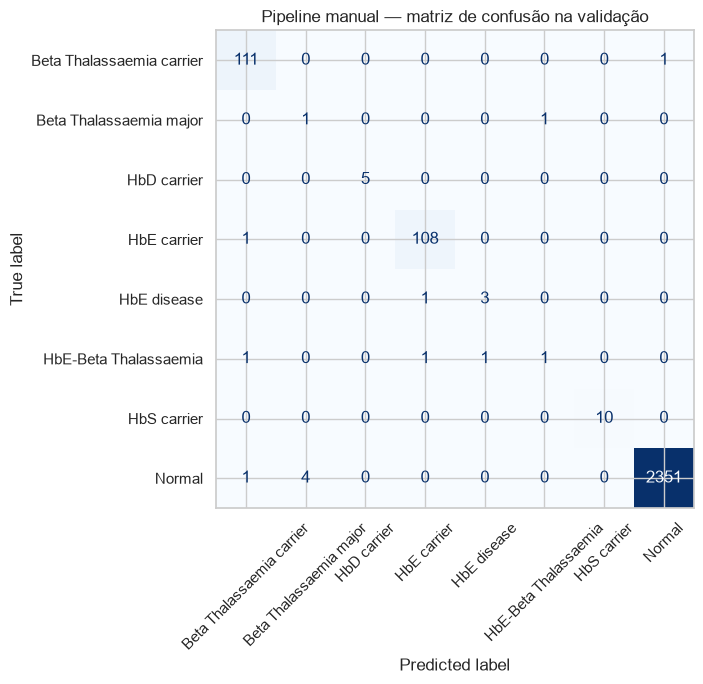

In [9]:
manual = modelos["Pipeline manual (T1 corrigido)"]
y_val_pred = manual.predict(X_val)
rep = pd.DataFrame(classification_report(y_val, y_val_pred, labels=CLASSES, output_dict=True, zero_division=0)).T
rep.to_csv(RESULTS / "relatorio_por_classe_validacao.csv")
display(rep.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(confusion_matrix(y_val, y_val_pred, labels=CLASSES), display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d")
ax.set_title("Pipeline manual — matriz de confusão na validação")
plt.tight_layout(); plt.savefig(RESULTS / "matriz_confusao_validacao.png", dpi=150); plt.show()

**Leitura:** o F1 ponderado fica próximo da acurácia porque `Normal` tem ~90% do suporte; o F1 macro dá o mesmo peso às classes raras (por exemplo, `HbE-Beta Thalassaemia` e `Beta Thalassaemia major`, com 3–4 exemplos na validação), e é nelas que o pipeline erra. Essa diferença explica possíveis inversões de ordem entre os sistemas quando se troca a métrica (Seção 5.1 do enunciado).

## 6. Avaliação única no conjunto de teste

**Critério declarado antes de consultar o teste:** o pipeline manual avaliado é exatamente a configuração final do Trabalho 1, ajustada somente no treino. Não há escolha feita com a validação; ela serviu apenas para conferir a reprodução. O baseline é a classe majoritária do treino.

O resultado é salvo em `resultados/manual/metricas_teste.csv`. Com `RUN_LONG = False`, o arquivo salvo é carregado e o teste **não é consultado de novo**.

In [10]:
test_path = RESULTS / "metricas_teste.csv"
if RUN_LONG or not test_path.exists():
    test_rows = []
    for nome, mk in SISTEMAS.items():
        _, row, proba_df = fit_and_eval(nome, mk, X_train, y_train, X_test, y_test, "test")
        test_rows.append(row)
        slug = "baseline" if "Baseline" in nome else "manual"
        proba_df.to_csv(RESULTS / f"predicoes_teste_{slug}.csv", index_label="row_index")
    test_metrics = pd.DataFrame(test_rows)
    test_metrics.to_csv(test_path, index=False)
else:
    test_metrics = pd.read_csv(test_path)

comparacao_t1 = pd.DataFrame([
    {"versão": "T1 original (ajuste em treino + validação)", "f1_macro_teste": T1_ORIGINAL["test_f1_macro_treino+val"]},
    {"versão": "T2 corrigido (ajuste só no treino)",
     "f1_macro_teste": test_metrics.loc[test_metrics.sistema.str.startswith("Pipeline"), "f1_macro"].item()},
])
comparacao_t1.to_csv(RESULTS / "t1_original_vs_corrigido.csv", index=False)
display(comparacao_t1.round(4))
test_metrics.round(4)

,versão,f1_macro_teste
0,T1 original (ajuste em treino + validação),0.9056
1,T2 corrigido (ajuste só no treino),0.8961


,sistema,subconjunto,f1_macro,f1_weighted,accuracy,balanced_accuracy,precision_macro,recall_macro,tempo_ajuste_s,tempo_inferencia_s,pico_memoria_mb
0,Baseline (classe majoritária),test,0.1188,0.8600,0.9051,0.1250,0.1131,0.1250,0.0327,0.0147,263.6602
1,Pipeline manual (T1 corrigido),test,0.8961,0.9974,0.9965,0.9673,0.8841,0.9673,4.5665,0.0603,285.9062


## 7. Interpretabilidade: importância por permutação na validação

Seção 5.5 do enunciado: `sklearn.inspection.permutation_importance` sobre o pipeline **inteiro** (as colunas embaralhadas são os atributos brutos, antes do pré-processamento), com F1 macro como métrica, 10 repetições e semente 42. Quanto maior a queda do F1 macro ao embaralhar um atributo, mais o modelo depende dele.

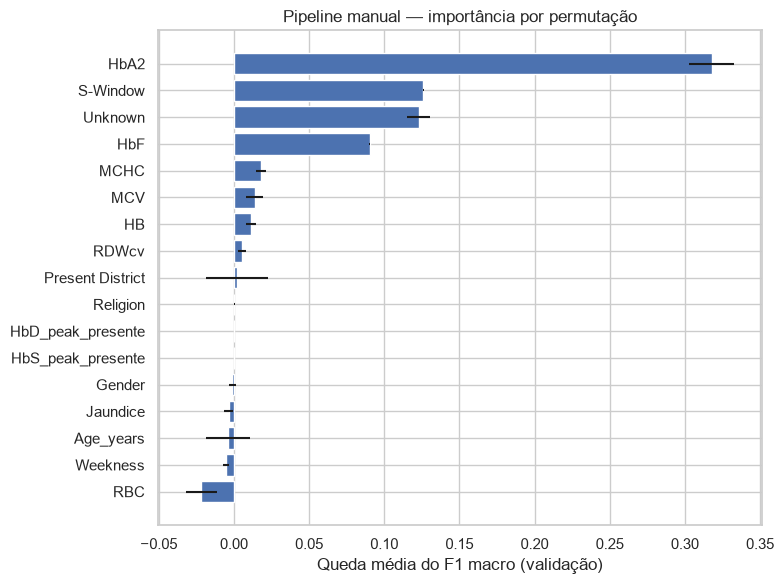

,atributo,queda_f1_macro_media,queda_f1_macro_dp
0,HbA2,0.3179,0.0151
1,S-Window,0.1261,0.0005
2,Unknown,0.1229,0.0076
3,HbF,0.0904,0.0004
4,MCHC,0.0179,0.0033
5,MCV,0.0138,0.0055
6,HB,0.0110,0.0033
7,RDWcv,0.0051,0.0027
8,Present District,0.0020,0.0208
9,Religion,0.0003,0.0006


In [11]:
pi_path = RESULTS / "importancia_permutacao_validacao.csv"
if RUN_LONG or not pi_path.exists():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pi = permutation_importance(manual, X_val, y_val, scoring="f1_macro",
                                    n_repeats=10, random_state=SEED, n_jobs=1)
    importancias = (pd.DataFrame({"atributo": X_val.columns,
                                  "queda_f1_macro_media": pi.importances_mean,
                                  "queda_f1_macro_dp": pi.importances_std})
                    .sort_values("queda_f1_macro_media", ascending=False).reset_index(drop=True))
    importancias.to_csv(pi_path, index=False)
else:
    importancias = pd.read_csv(pi_path)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importancias["atributo"][::-1], importancias["queda_f1_macro_media"][::-1],
        xerr=importancias["queda_f1_macro_dp"][::-1])
ax.set_xlabel("Queda média do F1 macro (validação)")
ax.set_title("Pipeline manual — importância por permutação")
plt.tight_layout(); plt.savefig(RESULTS / "importancia_permutacao_validacao.png", dpi=150); plt.show()
importancias.round(4)

Estrutura do modelo: coeficientes da regressão logística por classe (atributos já transformados). Serve para confrontar a importância por permutação com o que o modelo linear usa internamente.

In [12]:
clf = manual.named_steps["classifier"]
nomes = manual.named_steps["preprocessor"].get_feature_names_out()
coef = pd.DataFrame(clf.coef_, index=clf.classes_, columns=nomes)
top = coef.abs().mean().sort_values(ascending=False).rename("|coef| médio entre classes")
print(f"Modelo: LogisticRegression multinomial, {coef.shape[1]} atributos transformados, {coef.shape[0]} classes")
top.head(15).round(3).to_frame()

Modelo: LogisticRegression multinomial, 32 atributos transformados, 8 classes


,|coef| médio entre classes
HbA2,26.353
Weekness_No,8.528
Jaundice_No,8.402
Unknown,7.167
Religion_Hinduism,5.726
HbF,5.634
S-Window,5.125
Present District_bit0,4.888
Gender_Male,4.870
Present District_bit3,4.306


## 8. Efeito do atributo derivado no pipeline manual

Mesmo pipeline, variando **apenas** a presença de `HbS_peak_presente` e `HbD_peak_presente`. Medimos na CV de 5 folds do treino e na validação (nunca no teste), para servir de referência ao experimento obrigatório com as ferramentas.

In [13]:
abl_path = RESULTS / "ablacao_atributo_derivado.csv"
if RUN_LONG or not abl_path.exists():
    rows = []
    for com, feats in ((True, FEATURES_T1), (False, FEATURES_SEM_DERIVADO)):
        pipe = build_manual_pipeline(with_derived=com)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            s = cross_val_score(pipe, X_train[feats], y_train, cv=cv, scoring="f1_macro", n_jobs=1)
            pv = clone(pipe).fit(X_train[feats], y_train).predict(X_val[feats])
        rows.append({"atributo_derivado": "com" if com else "sem",
                     "cv_f1_macro_media": s.mean(), "cv_f1_macro_dp": s.std(ddof=1),
                     "val_f1_macro": compute_metrics(y_val, pv, CLASSES)["f1_macro"]})
    ablacao = pd.DataFrame(rows); ablacao.to_csv(abl_path, index=False)
else:
    ablacao = pd.read_csv(abl_path)
ablacao.round(4)

,atributo_derivado,cv_f1_macro_media,cv_f1_macro_dp,val_f1_macro
0,com,0.8982,0.0407,0.7920
1,sem,0.8695,0.0365,0.8049


## 9. Resumo para o notebook de consolidação

Tabela única com o que o Lucas precisa para a comparação geral, e um JSON com versões, hardware e configuração.

In [14]:
resumo = pd.concat([val_metrics, test_metrics], ignore_index=True)
resumo.insert(1, "budget", "—")
resumo.insert(1, "versao", f"scikit-learn {sklearn.__version__} / imbalanced-learn {imblearn.__version__}")
resumo.insert(2, "modelo_vencedor", np.where(resumo.sistema.str.startswith("Pipeline"),
              "SMOTE + LogisticRegression (C≈965,4, sem intercepto)", "DummyClassifier(most_frequent)"))
resumo.to_csv(RESULTS / "resumo_manual.csv", index=False)

meta = {"hardware": HW, "versoes": VERSOES, "seed": SEED, "lr_params": T1_LR_PARAMS,
        "features": FEATURES_T1, "t1_original": T1_ORIGINAL,
        "metodo_memoria": "pico de RSS (processo + subprocessos) amostrado a cada 50 ms com psutil"}
(RESULTS / "metadados_manual.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print("Arquivos em resultados/manual/:", sorted(p.name for p in RESULTS.iterdir()))
resumo.round(4)

Arquivos em resultados/manual/: ['ablacao_atributo_derivado.csv', 'importancia_permutacao_validacao.csv', 'importancia_permutacao_validacao.png', 'matriz_confusao_validacao.png', 'metadados_manual.json', 'metricas_teste.csv', 'metricas_validacao.csv', 'posicionamento_artigo.csv', 'predicoes_teste_baseline.csv', 'predicoes_teste_manual.csv', 'predicoes_val_baseline.csv', 'predicoes_val_manual.csv', 'relatorio_por_classe_validacao.csv', 'resumo_manual.csv', 't1_original_vs_corrigido.csv']


,sistema,versao,modelo_vencedor,budget,subconjunto,f1_macro,f1_weighted,accuracy,balanced_accuracy,precision_macro,recall_macro,tempo_ajuste_s,tempo_inferencia_s,pico_memoria_mb
0,Baseline (classe majoritária),scikit-learn 1.9.1 / imbalanced-learn 0.14.2,DummyClassifier(most_frequent),—,val,0.1188,0.8605,0.9055,0.1250,0.1132,0.1250,0.0238,0.0146,251.3867
1,Pipeline manual (T1 corrigido),scikit-learn 1.9.1 / imbalanced-learn 0.14.2,"SMOTE + LogisticRegression (C≈965,4, sem inter...",—,val,0.7920,0.9956,0.9954,0.8100,0.8006,0.8100,3.5719,0.0414,280.8828
2,Baseline (classe majoritária),scikit-learn 1.9.1 / imbalanced-learn 0.14.2,DummyClassifier(most_frequent),—,test,0.1188,0.8600,0.9051,0.1250,0.1131,0.1250,0.0327,0.0147,263.6602
3,Pipeline manual (T1 corrigido),scikit-learn 1.9.1 / imbalanced-learn 0.14.2,"SMOTE + LogisticRegression (C≈965,4, sem inter...",—,test,0.8961,0.9974,0.9965,0.9673,0.8841,0.9673,4.5665,0.0603,285.9062
